[![preview notebook](https://img.shields.io/static/v1?label=render%20on&logo=github&color=87ce3e&message=GitHub)](https://github.com/open-atmos/PySDM/blob/main/examples/PySDM_examples/featured/Berry_1967/fig_6.ipynb)
[![launch on mybinder.org](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/open-atmos/PySDM.git/main?urlpath=lab/tree/examples/PySDM_examples/featured/Berry_1967/fig_6.ipynb)
[![launch on Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/open-atmos/PySDM/blob/main/examples/PySDM_examples/featured/Berry_1967/fig_6.ipynb)

#### based on Fig. 6 from Berry 1967 (J. Atmos. Sci. 24)  "_Cloud Droplet Growth by Collection_"   
https://doi.org/10.1175/1520-0469(1967)024%3C0688:CDGBC%3E2.0.CO;2

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from open_atmos_jupyter_utils import show_plot

from PySDM import Formulae
from PySDM.physics import si

In [2]:
def formulae_maker(params):
    return Formulae(
        collision_kernel='Berry1967',
        constants={
            'KERNEL_BERRY_A': 1,
            'KERNEL_BERRY_B': 1,
            'KERNEL_BERRY_D1': params[0],
            'KERNEL_BERRY_D2': params[1],
            'KERNEL_BERRY_E1': params[2],
            'KERNEL_BERRY_E2': params[3],
            'KERNEL_BERRY_F1': params[4],
            'KERNEL_BERRY_F2': params[5],
            'KERNEL_BERRY_G1': params[6],
            'KERNEL_BERRY_G2': params[7],
            'KERNEL_BERRY_G3': params[8],
            'KERNEL_BERRY_Mf': params[9],
            'KERNEL_BERRY_Mg': params[10],
            'KERNEL_BERRY_unit': 1 * si.um,        
        }
    )

def formulae_caller(formulae, r1, r2):
    return (formulae.collision_kernel.liquid_liquid(r1, r2, 1, 0, np.nan, np.nan) / np.pi / max(r1, r2) ** 2)**.5

def print_collection_efficiency_portrait(params):
    size = 2 * 5.236
    plt.figure(figsize=(size / 2, size))
    points = 200
    Y_c = np.zeros(points)
    x_values = np.linspace(0, 1, points)
    formulae = formulae_maker(params)
    for r1 in (
        radius * si.um for radius in (8, 10, 14, 16, 20, 30, 40, 60, 80, 136)
    ):
        for i, _ in enumerate(x_values):
            r2 = x_values[i] * r1
            Y_c[i : i + 1] = formulae_caller(formulae, r1, r2)
        plt.plot(x_values, Y_c, label=f"{r1 / si.um}um")
    xticks = np.arange(11) / 10
    yticks = np.arange(21) / 10
    plt.xticks(xticks, xticks)
    plt.yticks(yticks, yticks)
    plt.xlim(xticks[0], xticks[-1])
    plt.ylim(yticks[0], yticks[-1])
    plt.grid()
    plt.plot([0, 1], [1, 2], color='k')
    show_plot("berry_fig_6.pdf")

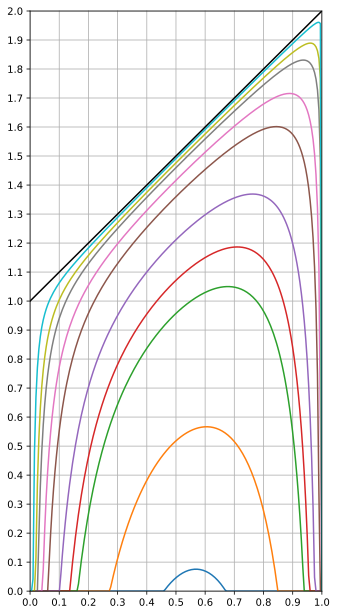

In [6]:
params = -7, 1.78, -20.5, 1.73, 0.26, 1.47, 1, 0.82, -0.003, 4.4, 8
print_collection_efficiency_portrait(params)

In [10]:
expected = np.array([
    [0, 0, 8.3, 0, 0, 0],  # 8
    [0, 36, 55.6, 24, 0, 0],  # 10
    [27, 85, 105.3, 96.2, 49.6, 0],  # 14
    [46.6, 94.7, 116.5, 107.5, 84.2, 0],  # 16
    [70, 108.2, 130.8, 136, 112.8, 0],  # 20
    [117, 138, 158, 179, 189, 0],  # 136
]) / 100

def Y_c_portrait(params):
    Y_c = np.zeros(expected.shape)
    formulae = formulae_maker(params)
    for i, r1 in enumerate(np.array((8, 10, 14, 16, 20, 136)) * si.um):
        for j, pj in enumerate((0.2, 0.4, 0.6, 0.8, 0.9, 1.0)):
            r2 = pj * r1
            Y_c[i : i + 1, j] = formulae_caller(formulae, r1, r2)
    return Y_c

Y_c = Y_c_portrait(params)
error = np.sum((Y_c - expected) ** 2)

assert error < .02